# Capítulo 11 · Probabilidade: caderno complementar
*Ciência de Dados e Inteligência Artificial em Saúde, Volume 1*

> **Este caderno acompanha o capítulo do livro; não o reproduz.** Definições, deduções e explicações estão no livro. Aqui você executa os cálculos do caso e confere os números. Todos os dados são **sintéticos**; nenhum paciente real aparece.

A **Parte A** percorre o caso do capítulo, uma maternidade pública com 5.000 registros de partos, pelas quatro perguntas do diretor. A **Parte B** traz o código e o resultado de cada um dos doze exercícios do capítulo (os enunciados estão no livro). Execute as células em ordem. As saídas do código usam ponto decimal.

## Parte A. O caso

**Dados.** `data/deliveries.csv`: uma linha por parto. `stay_days` é a internação puerperal inicial (dias de reinternação não entram); os 4 dias financiados são uma hipótese didática. Cada alerta de monitorização fetal acrescenta um dia-leito materno, já incluído em `stay_days`. `acidemia` é um indicador binário (pH arterial do cordão abaixo de 7,10); não há valores medidos de pH.

**Perguntas do diretor.** P1 com que frequência a internação passa de 4 dias · P2 quem tem internação longa · P3 o que o alerta acrescenta em dias-leito · P4 seleção e amostragem justas · depois, o plano de leitos.

In [1]:
import random
from math import comb, factorial, perm

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 9, "axes.titlesize": 10})
INK, MUTED = "#222222", "#8a8a8a"

df = pd.read_csv("data/deliveries.csv")
X = df["stay_days"] > 4                      # long stay
D = df["gestational_diabetes"] == "yes"
C = df["cesarean"] == "yes"
H = df["hemorrhage"] == "yes"
R = df["readmission"] == "yes"
T = df["return_to_theatre"] == "yes"
A = df["acidemia"] == "yes"
F = df["monitor_alert"] == "yes"
any_event = H | R | T
print(df.shape)
df.head()

(5000, 10)


,delivery_id,age_years,gestational_diabetes,cesarean,hemorrhage,readmission,return_to_theatre,stay_days,acidemia,monitor_alert
0,D0001,21,no,no,no,no,no,3,no,no
1,D0002,29,no,yes,no,no,no,4,no,no
2,D0003,24,yes,yes,no,yes,no,5,no,yes
3,D0004,22,no,no,no,no,no,3,no,no
4,D0005,48,no,no,no,no,no,2,no,no


### P1. Com que frequência a internação passa de 4 dias?

In [2]:
print(len(df), int(X.sum()), round(X.mean(), 4))
running = X.cumsum() / range(1, len(df) + 1)
checkpoints = (10, 50, 100, 500, 1000, 5000)
print([float(round(running.iloc[k - 1], 4)) for k in checkpoints])

5000 1216 0.2432
[0.3, 0.22, 0.23, 0.228, 0.248, 0.2432]


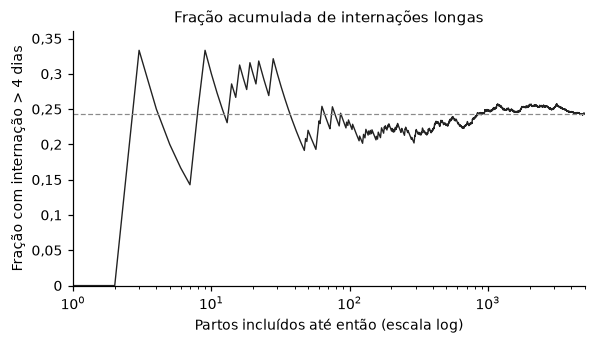

In [3]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(np.arange(1, len(df) + 1), running, color=INK, lw=0.9)
ax.axhline(X.mean(), color=MUTED, lw=0.8, ls=(0, (4, 2)))
ax.yaxis.set_major_formatter(__import__("matplotlib.ticker", fromlist=["FuncFormatter"]).FuncFormatter(lambda v, _: f"{v:g}".replace(".", ",")))
ax.set(xscale="log", xlim=(1, 5000), ylim=(0, 0.36), xlabel="Partos incluídos até então (escala log)",
       ylabel="Fração com internação > 4 dias", title="Fração acumulada de internações longas")
plt.show()

**Resultado:** 1.216 de 5.000 partos (0,2432).

In [4]:
print(int(H.sum()), int(R.sum()), int(T.sum()))
print(int((H & R).sum()), int((H & T).sum()), int(any_event.sum()))
p_h, p_r, p_t = H.mean(), R.mean(), T.mean()
p_hr, p_ht, p_rt, p_hrt = (H & R).mean(), (H & T).mean(), (R & T).mean(), (H & R & T).mean()
print(round(p_h + p_r + p_t, 4))
print(round(p_h + p_r + p_t - p_hr - p_ht - p_rt + p_hrt, 4))
print(round(any_event.mean(), 4), round((~any_event).mean(), 4))

299 398 83
133 54 592
0.156
0.1184
0.1184 0.8816


**Resultado:** soma das três probabilidades 0,1560; com as sobreposições removidas 0,1184 (contagem direta 0,1184); complemento 0,8816.

### P2. Quem tem internação longa?

In [5]:
groups = [("D", D), ("not D", ~D), ("C", C), ("not C", ~C),
          ("any H/R/T", any_event), ("no H/R/T", ~any_event)]
for name, group in groups:
    print(name, int(group.sum()), int((X & group).sum()), f"{X[group].mean():.4f}")
print("D and X", f"{(D & X).mean():.4f}")

D 809 396 0.4895
not D 4191 820 0.1957
C 1499 851 0.5677
not C 3501 365 0.1043
any H/R/T 592 335 0.5659
no H/R/T 4408 881 0.1999
D and X 0.0792


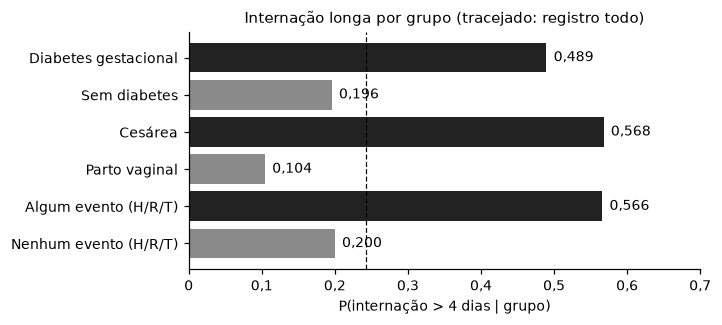

In [6]:
names_pt = {"D": "Diabetes gestacional", "not D": "Sem diabetes", "C": "Cesárea", "not C": "Parto vaginal",
            "any H/R/T": "Algum evento (H/R/T)", "no H/R/T": "Nenhum evento (H/R/T)"}
labels = [names_pt[g[0]] for g in groups]
vals = [X[g[1]].mean() for g in groups]
fig, ax = plt.subplots(figsize=(6, 2.8))
bars = ax.barh(labels[::-1], vals[::-1], color=[MUTED, INK] * 3)
ax.axvline(X.mean(), color="black", lw=0.8, ls=(0, (4, 2)))
for b, v in zip(bars, vals[::-1]):
    ax.text(v + 0.01, b.get_y() + b.get_height() / 2, f"{v:.3f}".replace(".", ","), va="center")
ax.xaxis.set_major_formatter(__import__("matplotlib.ticker", fromlist=["FuncFormatter"]).FuncFormatter(lambda v, _: f"{v:g}".replace(".", ",")))
ax.set(xlim=(0, 0.7), xlabel="P(internação > 4 dias | grupo)", title="Internação longa por grupo (tracejado: registro todo)")
plt.show()

In [7]:
print(f"{H.mean() * R.mean():.8f}", f"{(H & R).mean():.4f}")
print(f"{R[H].mean():.4f}", f"{R[~H].mean():.4f}")
chain = D.mean() * H[D].mean() * R[D & H].mean()
print(f"{chain:.4f}", f"{(D & H & R).mean():.4f}")

0.00476008 0.0266
0.4448 0.0564
0.0090 0.0090


In [8]:
p_x = X[D].mean() * D.mean() + X[~D].mean() * (~D).mean()
print(f"{p_x:.4f}")
for name, group in [("D", D), ("C", C)]:
    posterior = X[group].mean() * group.mean() / p_x
    print(name, f"{posterior:.4f}", f"{group[X].mean():.4f}")

0.2432
D 0.3257 0.3257
C 0.6998 0.6998


**Resultado:** internação longa em 396/809 com diabetes vs 820/4.191 sem; 851/1.499 cesáreas vs 365/3.501 partos vaginais; 335/592 com algum evento adverso registrado. Entre as internações longas: 396/1.216 com diabetes, 851/1.216 cesáreas.

### P3. O que o alerta acrescenta em dias-leito?

In [9]:
print(int((A & F).sum()), int((A & ~F).sum()), int((~A & F).sum()), int((~A & ~F).sum()))
sens = F[A].mean()
spec = (~F)[~A].mean()
prior = A.mean()
posterior = sens * prior / (sens * prior + (1 - spec) * (1 - prior))
print(f"{sens:.4f}", f"{spec:.4f}", f"{prior:.4f}")
print(f"{posterior:.4f}", f"{A[F].mean():.4f}")

197 47 465 4291
0.8074 0.9022 0.0488
0.2976 0.2976


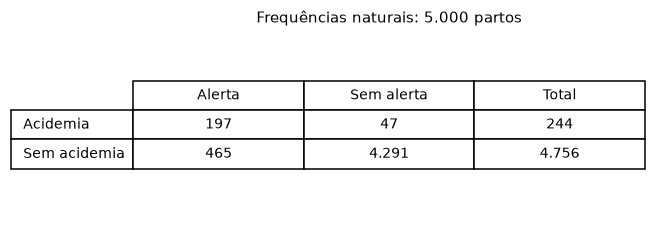

In [10]:
cell = pd.crosstab(A.map({True: "Acidemia", False: "Sem acidemia"}), F.map({True: "Alerta", False: "Sem alerta"}))
cell = cell.loc[["Acidemia", "Sem acidemia"], ["Alerta", "Sem alerta"]]
fig, ax = plt.subplots(figsize=(6, 2.2)); ax.axis("off")
t = ax.table(cellText=[[f"{v:,}".replace(",", ".") for v in row] + [f"{row.sum():,}".replace(",", ".")] for _, row in cell.iterrows()],
             rowLabels=cell.index, colLabels=list(cell.columns) + ["Total"], loc="center", cellLoc="center")
t.scale(1, 1.6); ax.set_title("Frequências naturais: 5.000 partos")
plt.show()

In [11]:
base_stay = df["stay_days"] - F.astype(int)
added_days = df["stay_days"] - base_stay
excess_added = ((df["stay_days"] - 4).clip(lower=0) - (base_stay - 4).clip(lower=0))
crossed = F & (base_stay <= 4) & X
print(int(added_days.sum()), int(added_days[~A].sum()))
print(int(excess_added.sum()), int(crossed.sum()))
print(int((F & X).sum()), int(F.sum()), f"{X[F].mean():.3f}")
print(int((~F & X).sum()), int((~F).sum()), f"{X[~F].mean():.3f}")

662 465
282 138
282 662 0.426
934 4338 0.215


**Resultado:** 662 alertas acrescentam 662 dias-leito maternos, 465 deles após partos sem acidemia; 282 dias acrescentados caem além do 4º dia; 138 internações passam de 4 dias por causa do dia acrescentado. O registro não tem efeitos de tratamento, então estas contagens não mostram se a observação era necessária.

### P4. Seleção e amostragem justas (insumos de planejamento hipotéticos)

In [12]:
print(comb(12, 6), 2 * comb(9, 3))
print(f"{2 * comb(9, 3) / comb(12, 6):.4f}")
print(factorial(12), perm(12, 2))
none = comb(388, 20) / comb(400, 20)
print(f"{none:.4f}", f"{1 - none:.4f}")

924 168
0.1818
479001600 132
0.5356 0.4644


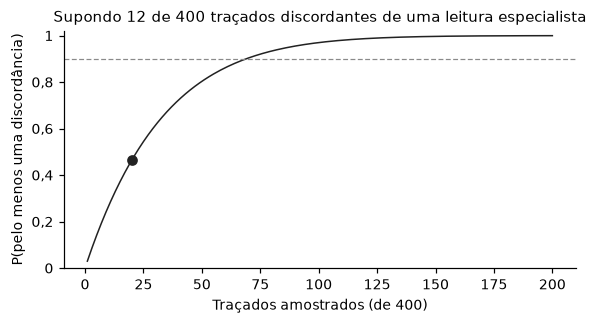

In [13]:
n = np.arange(1, 201)
p_detect = 1 - np.array([comb(388, k) / comb(400, k) for k in n])
fig, ax = plt.subplots(figsize=(6, 2.8))
ax.plot(n, p_detect, color=INK, lw=1); ax.axhline(0.9, color=MUTED, lw=0.8, ls=(0, (4, 2)))
ax.plot([20], [1 - none], "o", color=INK)
ax.yaxis.set_major_formatter(__import__("matplotlib.ticker", fromlist=["FuncFormatter"]).FuncFormatter(lambda v, _: f"{v:g}".replace(".", ",")))
ax.set(xlabel="Traçados amostrados (de 400)", ylabel="P(pelo menos uma discordância)", ylim=(0, 1.02),
       title="Supondo 12 de 400 traçados discordantes de uma leitura especialista")
plt.show()

**Resultado:** 924 sorteios do piloto, 168 mantendo três equipes nomeadas juntas (0,1818); 479.001.600 ordens de treinamento; 20 de 400 traçados encontram uma discordância com probabilidade 0,4644.

### Plano de leitos

In [14]:
mean_stay = df["stay_days"].mean()
print(int(df["stay_days"].sum()))
print(f"{mean_stay:.2f}", f"{4 - mean_stay:.2f}")

17666
3.53 0.47


**Resultado:** 17.666 dias-leito de internação inicial; média de 3,53 dias, 0,47 abaixo do limite hipotético. É apenas aritmética, não evidência de capacidade sobrando.

## Parte B. Soluções dos exercícios

Os enunciados estão no livro. Os exercícios marcados *alt.* usam um cenário alternativo definido no enunciado.

### Exercício 1. Espaço amostral

**Resultado:** exercício conceitual; a resposta está no livro.

### Exercício 2. As oito probabilidades

In [15]:
counts = df.groupby(["hemorrhage", "readmission", "return_to_theatre"]).size()
for outcome, count in counts.items():
    code_ = "".join("Y" if item == "yes" else "N" for item in outcome)
    print(code_, int(count), f"{count / len(df):.4f}")
print("Total", int(counts.sum()), f"{counts.sum() / len(df):.4f}")

NNN 4408 0.8816
NNY 28 0.0056
NYN 264 0.0528
NYY 1 0.0002
YNN 144 0.0288
YNY 22 0.0044
YYN 101 0.0202
YYY 32 0.0064
Total 5000 1.0000


**Resultado:** reinternação isolada é a descrição mais comum com evento adverso (264, 0,0528), depois hemorragia isolada (144, 0,0288).

### Exercício 3. Hemorragia ou retorno ao centro cirúrgico

In [16]:
print(int((H | T).sum()), f"{(H | T).mean():.4f}")
print(f"{H.mean() * T.mean():.8f}", f"{(H & T).mean():.4f}")

328 0.0656
0.00099268 0.0108


**Resultado:** 328 partos (0,0656); produto sob independência 0,00099 vs observado 0,0108.

### Exercício 4. Tipo de parto e internação longa

In [17]:
p_x_c = X[C].mean()
p_x_not_c = X[~C].mean()
p_x = p_x_c * C.mean() + p_x_not_c * (~C).mean()
print(f"{p_x_c:.4f}", f"{p_x_not_c:.4f}", f"{p_x_c / p_x_not_c:.2f}")
print(f"{p_x_c * C.mean() / p_x:.4f}", f"{C[X].mean():.4f}")

0.5677 0.1043 5.45
0.6998 0.6998


**Resultado:** 0,5677 vs 0,1043 (razão 5,45); P(C|X) = 851/1.216 = 0,6998 por Bayes e por contagem.

### Exercício 5. Três eventos em sequência

In [18]:
chain = C.mean() * H[C].mean() * T[C & H].mean()
print(int(C.sum()), int((C & H).sum()), int((C & H & T).sum()))
print(f"{chain:.4f}", f"{(C & H & T).mean():.4f}")

1499 114 29
0.0058 0.0058


**Resultado:** (1.499/5.000) × (114/1.499) × (29/114) = 29/5.000 = 0,0058.

### Exercício 6. Alerta alternativo (alt.)

In [19]:
scenarios = [(0.95, A.mean()), (0.95, 0.20), (0.80, A.mean())]
for sensitivity, prevalence in scenarios:
    ppv = sensitivity * prevalence / (sensitivity * prevalence + 0.10 * (1 - prevalence))
    print(f"{sensitivity:.2f}", f"{prevalence:.4f}", f"{ppv:.4f}")

0.95 0.0488 0.3277
0.95 0.2000 0.7037
0.80 0.0488 0.2910


**Resultado:** VPP 0,3277, 0,7037 e 0,2910 sob os desempenhos supostos.

### Exercício 7. Frequências naturais reescaladas

In [20]:
scale = 10_000 / len(df)
table = pd.DataFrame({"Alerta": [(A & F).sum() * scale, (~A & F).sum() * scale],
                      "Sem alerta": [(A & ~F).sum() * scale, (~A & ~F).sum() * scale]},
                     index=["Acidemia", "Sem acidemia"]).round().astype(int)
table["Total"] = table.sum(axis=1)
table.loc["Total"] = table.sum()
table

,Alerta,Sem alerta,Total
Acidemia,394,94,488
Sem acidemia,930,8582,9512
Total,1324,8676,10000


**Resultado:** 1.324 alertas por 10.000 partos: 394 com acidemia, 930 sem (930 dias-leito acrescentados).

### Exercício 8. Ordem de quatro equipes selecionadas

In [21]:
from itertools import permutations
orders = list(permutations(["T9", "T10", "T11", "T12"]))
first = sum(o[0] == "T12" for o in orders)
first_second = sum(o[0] == "T12" and o[1] == "T11" for o in orders)
last_two = sum(set(o[2:]) == {"T11", "T12"} for o in orders)
print(len(orders), first / len(orders), first_second / len(orders), last_two / len(orders))

24 0.25 0.08333333333333333 0.16666666666666666


**Resultado:** 24 ordens; 1/4, 1/12 e 1/6.

### Exercício 9. Amostra mínima de traçados

In [22]:
for n in range(1, 401):
    detection = 1 - comb(388, n) / comb(400, n)
    if detection >= 0.90:
        print(n, f"{detection:.5f}")
        previous = 1 - comb(388, n - 1) / comb(400, n - 1)
        print(n - 1, f"{previous:.5f}")
        break

69 0.90047
68 0.89674


**Resultado:** 69 traçados (0,90047); 68 dá 0,89674.

### Exercício 10. Marginais alternativas (alt.)

**Resultado:** exercício conceitual; a resposta está no livro.

### Exercício 11. Cinco anos de 200 partos (alt.)

In [23]:
rng = random.Random(10)
probability = float(X.mean())
annual_counts = [sum(rng.random() < probability for _ in range(200)) for _ in range(5)]
cumulative = 0
for year, count in enumerate(annual_counts, start=1):
    cumulative += count
    print(year, count, f"{count / 200:.4f}", f"{cumulative / (200 * year):.4f}")

1 43 0.2150 0.2150
2 55 0.2750 0.2450
3 47 0.2350 0.2417
4 41 0.2050 0.2325
5 45 0.2250 0.2310


**Resultado:** proporções anuais 0,2150, 0,2750, 0,2350, 0,2050, 0,2250; acumuladas 0,2150, 0,2450, 0,2417, 0,2325, 0,2310.

### Exercício 12. Tipos de probabilidade

In [24]:
print(int((H & D).sum()), int(D.sum()), int(H.sum()), int((A & F).sum()), int(F.sum()))

72 809 299 197 662


**Resultado:** as contagens por trás das cinco afirmações estão impressas acima (H e D, D, H, A e F, F); a classificação está no livro.

---
*Dados sintéticos (semente 11, `generate_data.py`). Apenas hipóteses didáticas; nada aqui é recomendação clínica nem estimativa para uma unidade real.*